# Пример расчета прямого и обратного прохода при обучении сети.

<img src='images/ris0_1.png' width=600, heigth=440> <br>
<img src='images/ris0_2.png' width=600, heigth=440> <br>
<img src='images/ris0_3.png' width=600, heigth=440> <br>
<img src='images/ris1_1.png' width=600, heigth=440> <br>
<img src='images/ris1_2.png' width=600, heigth=440> <br>


# Открытие датасета

# Импорты
Нужно установить PyTorch 

In [35]:
import math
import csv
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import gridspec



#---------
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
from torchvision import transforms
from torchvision.transforms.functional import normalize
import torchvision.datasets as dset

from torch.utils.data import Dataset, DataLoader
from torch.utils.data.sampler import SubsetRandomSampler, Sampler
from tqdm import tqdm
from sklearn.metrics import classification_report

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [36]:
#Возьмем данные из модуля datasets библиотеки Scikit-learn. Вначале загрузим их.
from sklearn import datasets
raw_data = datasets.load_wine()

In [37]:
# посмотрим на составляющие датасета
raw_data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

In [38]:
# определим тип данных нашего датасета
type(raw_data)

sklearn.utils._bunch.Bunch

In [39]:
# разбиение датасета на с цифрами на тестовый и обучающий
MNIST_train = torchvision.datasets.MNIST(root='./data', 
                                           train=True, 
                                           transform=transforms.ToTensor(),  
                                           download=True)
MNIST_test = torchvision.datasets.MNIST(root='./data', 
                                          train=False, 
                                          transform=transforms.ToTensor())


C:\Users\valentin\AppData\Local\Temp\ipykernel_12892\357252736.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  ax[i].imshow(np.array(MNIST_train[i][0][0]), 'gray')


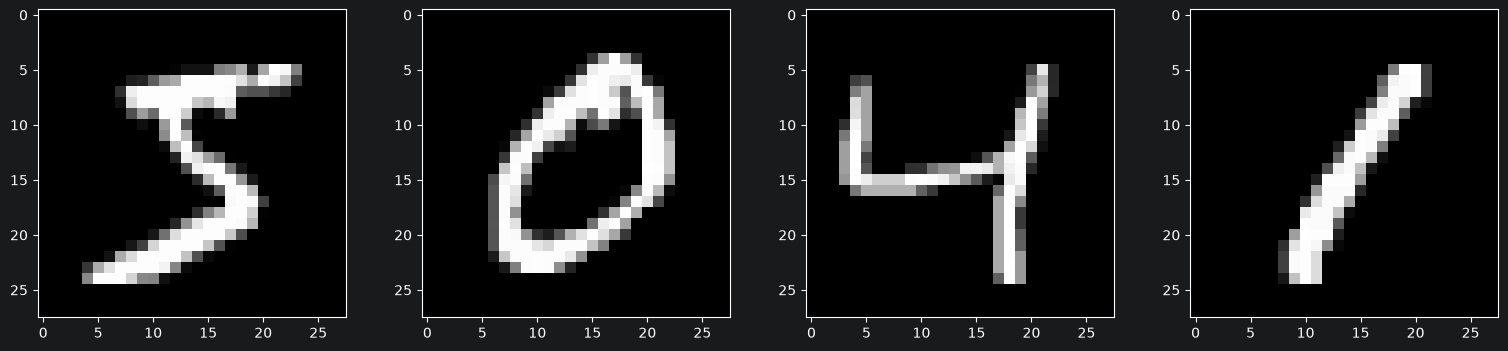

In [40]:
# отображение датасета с  цифрами
fig, gs = plt.figure(figsize=(19,4)), gridspec.GridSpec(1, 4) 
ax = []
for i in range(4):
    ax.append(fig.add_subplot(gs[i]))
    ax[i].imshow(np.array(MNIST_train[i][0][0]), 'gray')
plt.show()

In [41]:
# создание класса perceptron
class Perceptron(torch.nn.Module):
    def __init__(self, input_dim=784, num_layers=0,
            hidden_dim=64, output_dim=10, p=0.0, device='cpu'): 
        super(Perceptron, self).__init__()
        self.layers = torch.nn.Sequential()
        prev_size = input_dim 
        for i in range(num_layers):
            self.layers.add_module('layer{}'.format(i), torch.nn.Linear(prev_size, hidden_dim)) 
            self.layers.add_module('relu{}'.format(i), torch.nn.ReLU())
            self.layers.add_module('dropout{}'.format(i), torch.nn.Dropout(p=p)) 
            prev_size = hidden_dim
        self.layers.add_module('classifier',
            torch.nn.Linear(prev_size, output_dim))
        self.to(device)

    def forward(self, input):
        return self.layers(input)


In [42]:
# это объект, обозначающий устройство, на котором размещен или будет размещен torch.Tensor \
# Torch.device содержит тип устройства («процессор» или « cuda»)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 
device


device(type='cpu')

In [43]:
# Создание модели без внутренних слоев 
model = Perceptron(device=device) 
model

Perceptron(
  (layers): Sequential(
    (classifier): Linear(in_features=784, out_features=10, bias=True)
  )
)

In [44]:

model = Perceptron(num_layers=5, device=device) 
model

Perceptron(
  (layers): Sequential(
    (layer0): Linear(in_features=784, out_features=64, bias=True)
    (relu0): ReLU()
    (dropout0): Dropout(p=0.0, inplace=False)
    (layer1): Linear(in_features=64, out_features=64, bias=True)
    (relu1): ReLU()
    (dropout1): Dropout(p=0.0, inplace=False)
    (layer2): Linear(in_features=64, out_features=64, bias=True)
    (relu2): ReLU()
    (dropout2): Dropout(p=0.0, inplace=False)
    (layer3): Linear(in_features=64, out_features=64, bias=True)
    (relu3): ReLU()
    (dropout3): Dropout(p=0.0, inplace=False)
    (layer4): Linear(in_features=64, out_features=64, bias=True)
    (relu4): ReLU()
    (dropout4): Dropout(p=0.0, inplace=False)
    (classifier): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [45]:
# процедура терстирования модели 
def testing(model, dataset):
    generator = torch.utils.data.DataLoader(dataset, batch_size=64)
    pred = []
    real = []
    for x, y in tqdm(generator, leave=False):
        x = x.view([-1, 784]).to(device) 
        y = y.to(device)
        pred.extend(torch.argmax(model(x), dim=-1).cpu().numpy().tolist()) 
        real.extend(y.cpu().numpy().tolist())
    
    return np.mean(np.array(real) == np.array(pred)), classification_report(real, pred)


In [46]:
# процедура тренировки модели
def trainer(model, dataset, loss_function, optimizer, epochs): 
    for epoch in tqdm(range(epochs), leave=False):
        generator = torch.utils.data.DataLoader(dataset, batch_size=64,
            shuffle=True)

        for x, y in tqdm(generator, leave=False):
            optimizer.zero_grad() 
            x = x.view([-1, 784]).to(device) 
            y = y.to(device)
            output = model(x)
            loss = loss_function(output, y)
            loss.backward()
            optimizer.step()


In [47]:
model = Perceptron(num_layers=0, device=device)


In [48]:
# Результат, получаемый от необученной модели.
_ = model.eval()
acc, report = testing(model, MNIST_test) 
print(report)

              precision    recall  f1-score   support

           0       0.04      0.01      0.01       980
           1       0.26      0.20      0.23      1135
           2       0.05      0.06      0.05      1032
           3       0.12      0.05      0.07      1010
           4       0.07      0.19      0.11       982
           5       0.02      0.01      0.01       892
           6       0.13      0.41      0.20       958
           7       0.27      0.06      0.10      1028
           8       0.09      0.04      0.06       974
           9       0.11      0.07      0.08      1009

    accuracy                           0.11     10000
   macro avg       0.12      0.11      0.09     10000
weighted avg       0.12      0.11      0.09     10000



In [49]:
# Обучение модели
_ = model.train()
trainer(model=model,
    dataset=MNIST_train,
    loss_function=torch.nn.CrossEntropyLoss(),
    optimizer=torch.optim.Adam(model.parameters(), lr=0.001), 
    epochs=4)


100%|█████████▉| 934/938 [00:21<00:00, 45.68it/s]


In [50]:
# Результат обучения классификатора
_ = model.eval()
acc, report = testing(model, MNIST_test) 
print(report)

              precision    recall  f1-score   support

           0       0.94      0.98      0.96       980
           1       0.96      0.99      0.97      1135
           2       0.93      0.89      0.91      1032
           3       0.91      0.90      0.91      1010
           4       0.93      0.94      0.93       982
           5       0.88      0.89      0.89       892
           6       0.94      0.95      0.94       958
           7       0.95      0.91      0.93      1028
           8       0.89      0.87      0.88       974
           9       0.90      0.91      0.91      1009

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



Задание: С помощью нейронной сети классифицировать вина по качеству. Датасет взять из третьей работы. Разбить датасет на два класса по качеству вина. Качество вина до пяти включительно определить как первый класс, свыше пяти - как второй.
Представить основные показатели метода. Сравнить результат классификации с результатом из третьей работы.

Вариант выполнения: многоклассовая классификация, как в третьей работе. Каждая оценка качества вина (3-8) — отдельный класс, разбиение стратифицировано по этим классам.

In [51]:
df = pd.read_csv("data/wine/wine.csv")

### EDA

In [52]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [53]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [55]:
num_cols = df.columns[:-1]
target = df.columns[-1]

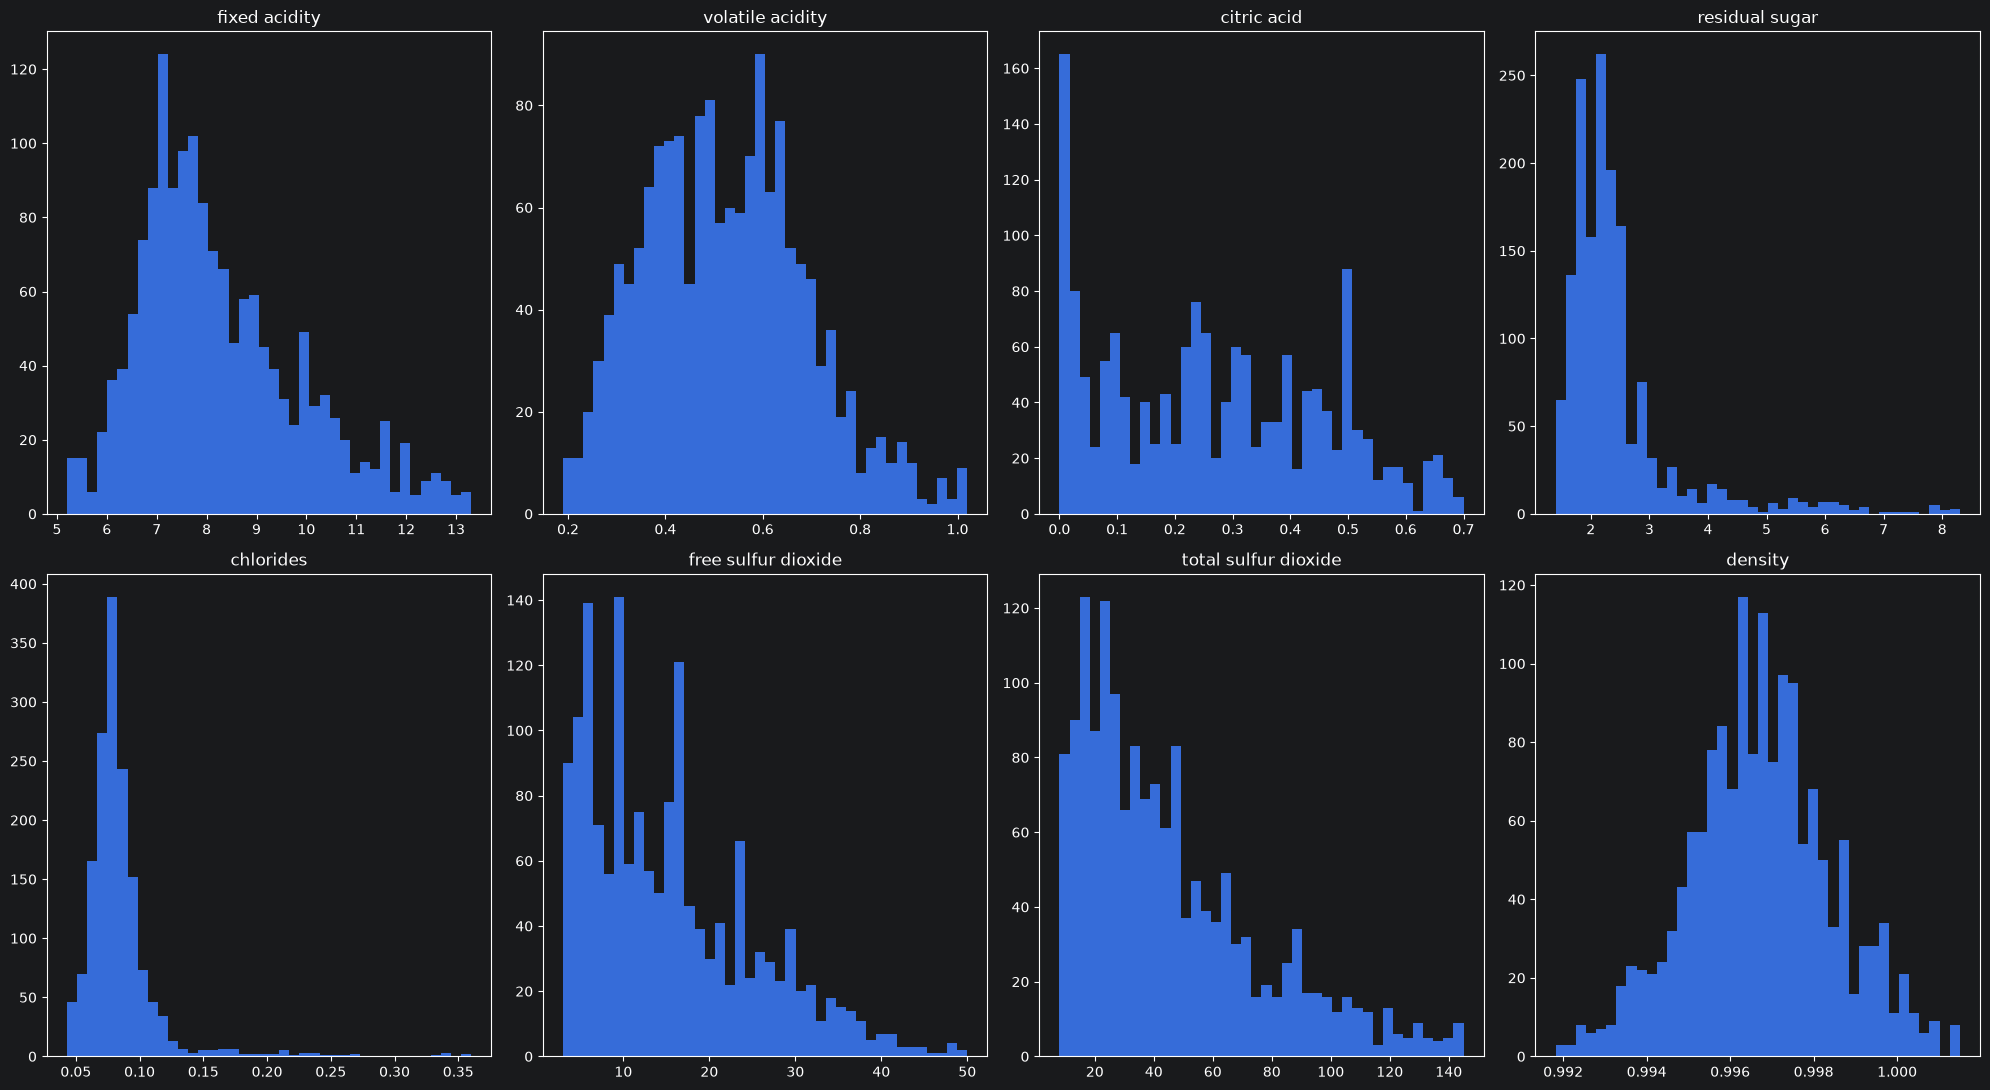

In [56]:
fig, axes = plt.subplots(2, 4, figsize=(20, 11))
for ax, c in zip(axes.ravel(), num_cols):
  s = df[c].dropna()
  ax.hist(s[(s >= s.quantile(0.01)) & (s <= s.quantile(0.99))], bins=40)
  ax.set_title(c)
plt.tight_layout()
plt.show()

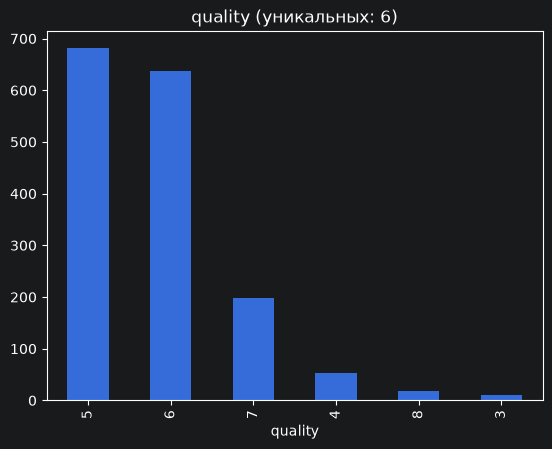

In [57]:

df[target].value_counts().head(15).plot(kind='bar')
plt.title(target + ' (уникальных: ' + str(df[target].nunique()) + ')')
plt.show()


### Препроцессинг

In [58]:
from sklearn.model_selection import train_test_split

print('Пропусков:', df.isna().sum().sum())
print('Дубликатов:', df.duplicated().sum())

df = df.drop_duplicates().dropna().reset_index(drop=True)

classes = np.sort(df[target].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X = df.drop(columns=[target])
y = df[target].map(class_to_idx)

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

distribution = pd.DataFrame({'train': y_train.value_counts().sort_index(),
                             'val': y_val.value_counts().sort_index(),
                             'test': y_test.value_counts().sort_index()})
distribution.index = classes

print('Классы качества:', classes.tolist())
print(x_train.shape, x_val.shape, x_test.shape)
print(distribution)

Пропусков: 0
Дубликатов: 240
Классы качества: [3, 4, 5, 6, 7, 8]
(815, 11) (272, 11) (272, 11)
   train  val  test
3      6    2     2
4     31   11    11
5    346  115   116
6    321  107   107
7    100   34    33
8     11    3     3


In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)

In [60]:
train_dataset = torch.utils.data.TensorDataset(
    torch.tensor(x_train_scaled, dtype=torch.float32),
    torch.tensor(y_train.values, dtype=torch.long))
val_dataset = torch.utils.data.TensorDataset(
    torch.tensor(x_val_scaled, dtype=torch.float32),
    torch.tensor(y_val.values, dtype=torch.long))
test_dataset = torch.utils.data.TensorDataset(
    torch.tensor(x_test_scaled, dtype=torch.float32),
    torch.tensor(y_test.values, dtype=torch.long))

input_dim = x_train_scaled.shape[1]

print('Размеры датасетов:', len(train_dataset), len(val_dataset), len(test_dataset))

Размеры датасетов: 815 272 272


### Модель
Многоклассовая сеть на классе `Perceptron`: 3 скрытых слоя по 256 нейронов (вместо 2 по 64), dropout 0.3 и 6 выходных нейронов (по одному на каждую оценку качества). Для обучения выделена валидационная выборка: по ней `ReduceLROnPlateau` снижает learning rate, когда val loss перестаёт улучшаться, а early stopping останавливает обучение и возвращает веса с наилучшим val loss. Метрики считаются теми же, что в третьей работе.

In [61]:
def predict_wine(model, dataset):
    generator = torch.utils.data.DataLoader(dataset, batch_size=64)
    proba = []
    real = []
    model.eval()
    with torch.no_grad():
        for x, y in generator:
            x = x.to(device)
            proba.append(torch.softmax(model(x), dim=-1).cpu().numpy())
            real.extend(y.numpy().tolist())
    return np.array(real), np.concatenate(proba)


def evaluate_loss(model, dataset, loss_function):
    generator = torch.utils.data.DataLoader(dataset, batch_size=64)
    total = 0.0
    with torch.no_grad():
        for x, y in generator:
            x = x.to(device)
            y = y.to(device)
            total += loss_function(model(x), y).item() * len(y)
    return total / len(dataset)


def trainer_wine(model, train_dataset, val_dataset, loss_function, optimizer,
                 scheduler, epochs, patience, min_delta=1e-4):
    history = {'train_loss': [], 'val_loss': [], 'lr': []}
    best_val = float('inf')
    best_state = None
    wait = 0

    for epoch in tqdm(range(epochs), leave=False):
        model.train()
        generator = torch.utils.data.DataLoader(train_dataset, batch_size=64,
            shuffle=True)
        epoch_loss = 0.0
        for x, y in generator:
            optimizer.zero_grad()
            x = x.to(device)
            y = y.to(device)
            loss = loss_function(model(x), y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(y)

        model.eval()
        train_loss = epoch_loss / len(train_dataset)
        val_loss = evaluate_loss(model, val_dataset, loss_function)
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['lr'].append(optimizer.param_groups[0]['lr'])

        if val_loss < best_val - min_delta:
            best_val = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

In [62]:
torch.manual_seed(42)
model_deep = Perceptron(input_dim=input_dim, num_layers=2, hidden_dim=64,
                        output_dim=n_classes, p=0.3, device=device)
model_deep

Perceptron(
  (layers): Sequential(
    (layer0): Linear(in_features=11, out_features=64, bias=True)
    (relu0): ReLU()
    (dropout0): Dropout(p=0.3, inplace=False)
    (layer1): Linear(in_features=64, out_features=64, bias=True)
    (relu1): ReLU()
    (dropout1): Dropout(p=0.3, inplace=False)
    (classifier): Linear(in_features=64, out_features=6, bias=True)
  )
)

Обучение остановлено на эпохе: 68
Лучшая эпоха: 53 | val loss: 0.9468


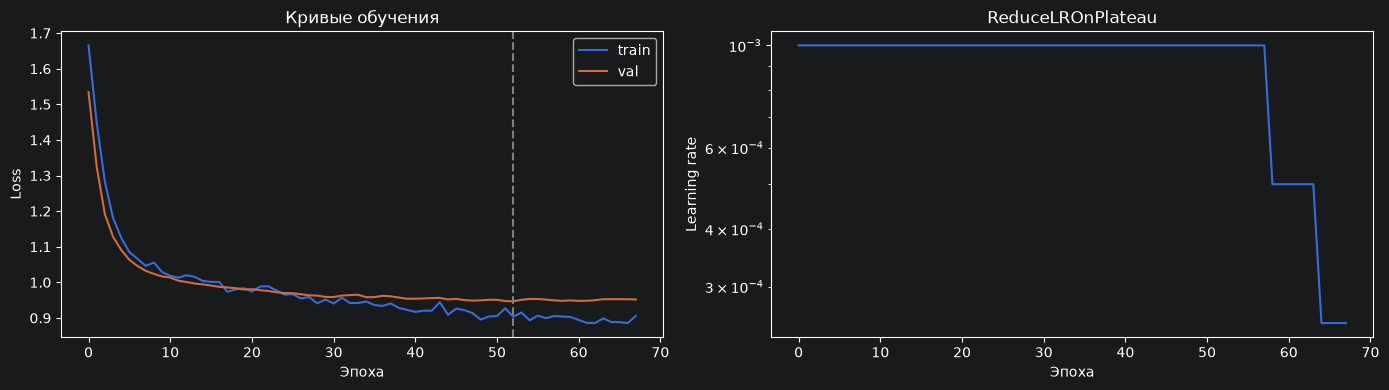

In [63]:
loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_deep.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5, min_lr=1e-6)

history = trainer_wine(model=model_deep,
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    loss_function=loss_function,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=300,
    patience=15)

best_epoch = int(np.argmin(history['val_loss'])) + 1
print('Обучение остановлено на эпохе:', len(history['val_loss']))
print('Лучшая эпоха:', best_epoch, '| val loss:', round(min(history['val_loss']), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].axvline(best_epoch - 1, color='gray', linestyle='--')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Loss')
axes[0].set_title('Кривые обучения')
axes[0].legend()
axes[1].plot(history['lr'])
axes[1].set_yscale('log')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Learning rate')
axes[1].set_title('ReduceLROnPlateau')
plt.tight_layout()
plt.show()

[[ 0  0  1  1  0  0]
 [ 0  0 10  1  0  0]
 [ 0  0 87 28  1  0]
 [ 0  0 36 63  8  0]
 [ 0  0  2 17 14  0]
 [ 0  0  0  1  2  0]]


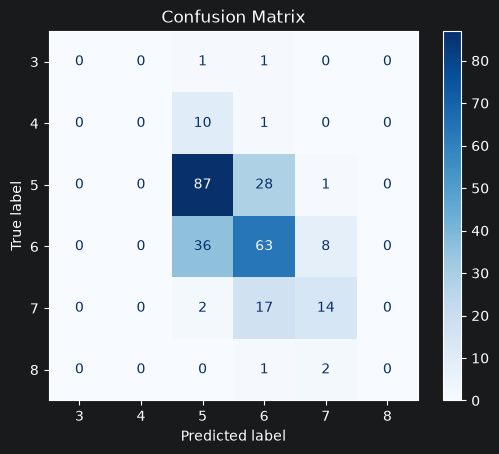

Accuracy: 0.6029
Precision (macro): 0.2945
Recall (macro): 0.2938
F1 (macro): 0.2919
Precision (weighted): 0.564
Recall (weighted): 0.6029
F1 (weighted): 0.5804
ROC-AUC (ovr, macro): 0.7596
ROC-AUC (ovr, weighted): 0.7645

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.64      0.75      0.69       116
           6       0.57      0.59      0.58       107
           7       0.56      0.42      0.48        33
           8       0.00      0.00      0.00         3

    accuracy                           0.60       272
   macro avg       0.29      0.29      0.29       272
weighted avg       0.56      0.60      0.58       272



In [64]:
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.preprocessing import label_binarize

labels = np.arange(n_classes)
class_names = [str(c) for c in classes]

y_true, y_proba = predict_wine(model_deep, test_dataset)
y_pred = y_proba.argmax(axis=1)

cm = confusion_matrix(y_true, y_pred, labels=labels)
print(cm)

disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(cmap='Blues')
disp.ax_.set_title('Confusion Matrix')
plt.show()

metrics_deep = {
    'Accuracy': accuracy_score(y_true, y_pred),
    'Precision (macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
    'Recall (macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
    'F1 (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
    'Precision (weighted)': precision_score(y_true, y_pred, average='weighted', zero_division=0),
    'Recall (weighted)': recall_score(y_true, y_pred, average='weighted', zero_division=0),
    'F1 (weighted)': f1_score(y_true, y_pred, average='weighted', zero_division=0),
    'ROC-AUC (ovr, macro)': roc_auc_score(y_true, y_proba, multi_class='ovr', average='macro', labels=labels),
    'ROC-AUC (ovr, weighted)': roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted', labels=labels),
}

for name, value in metrics_deep.items():
    print(name + ':', round(value, 4))
print()
print(classification_report(y_true, y_pred, labels=labels, target_names=class_names, zero_division=0))

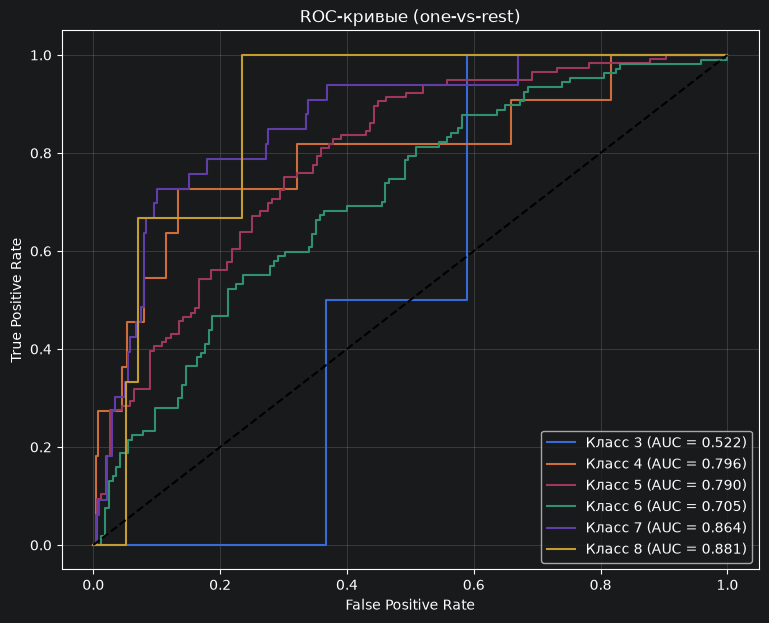

In [65]:
y_bin = label_binarize(y_true, classes=labels)

plt.figure(figsize=(9, 7))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, label=f'Класс {c} (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые (one-vs-rest)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

### Подбор порога по ROC
Для каждого класса (one-vs-rest) перебираем пороги из `roc_curve` и выбираем порог с максимальным F1. В третьей работе пороги подбирались прямо на тестовой выборке; здесь они подбираются на валидационной, а затем применяются к тестовой, чтобы оценка не была завышена. Итоговый weighted F1 считается как среднее F1 по классам с весами, равными числу объектов класса в тесте.

In [66]:
val_true, val_proba = predict_wine(model_deep, val_dataset)
val_bin = label_binarize(val_true, classes=labels)
supports = y_bin.sum(axis=0)

rows = []
best_thresholds = {}

for i, c in enumerate(classes):
    _, _, thr = roc_curve(val_bin[:, i], val_proba[:, i])
    thr = thr[1:]
    f1_val = [f1_score(val_bin[:, i], (val_proba[:, i] >= t).astype(int), zero_division=0) for t in thr]
    k = int(np.argmax(f1_val))
    best_thresholds[c] = thr[k]
    f1_test = f1_score(y_bin[:, i], (y_proba[:, i] >= thr[k]).astype(int), zero_division=0)
    rows.append({'класс': c, 'support': supports[i], 'порог': thr[k], 'f1 (val)': f1_val[k], 'f1 (test)': f1_test})

res = pd.DataFrame(rows)
weighted_f1_thr = np.average(res['f1 (test)'], weights=res['support'])

print(res.round(4).to_string(index=False))
print()
print('Weighted F1 при порогах, подобранных на val:', round(weighted_f1_thr, 4))
print('Weighted F1 у исходной модели:', round(metrics_deep['F1 (weighted)'], 4))

 класс  support  порог  f1 (val)  f1 (test)
     3        2 0.1254    0.5000     0.0000
     4       11 0.1093    0.2105     0.2703
     5      116 0.2708    0.7415     0.7216
     6      107 0.3388    0.6667     0.6176
     7       33 0.4115    0.6207     0.4333
     8        3 0.0260    0.0435     0.0976

Weighted F1 при порогах, подобранных на val: 0.6153
Weighted F1 у исходной модели: 0.5804


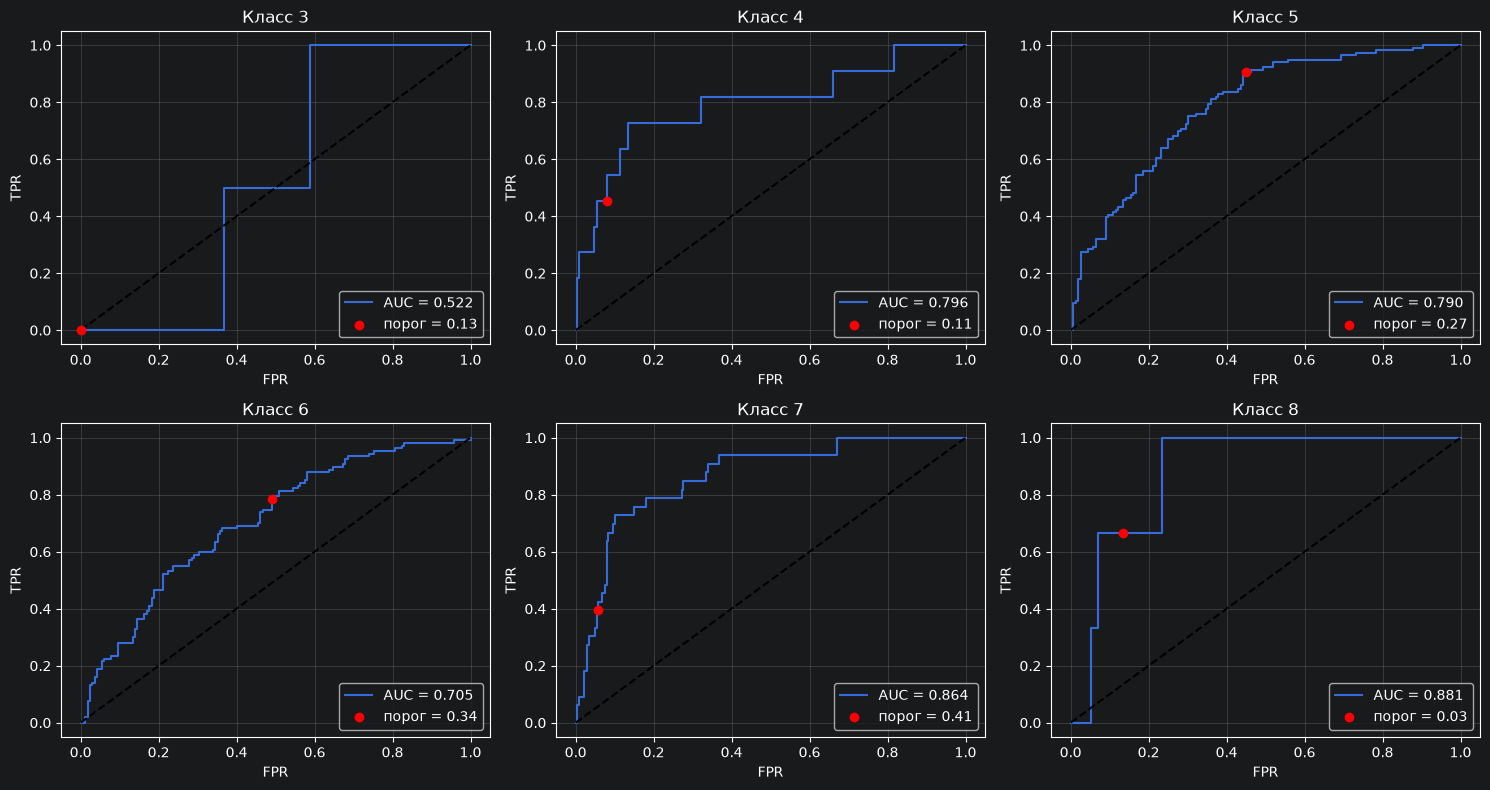

In [67]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (i, c) in zip(axes.ravel(), enumerate(classes)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
    t = best_thresholds[c]
    pred_c = (y_proba[:, i] >= t).astype(int)
    is_pos = y_bin[:, i] == 1
    ax.plot(fpr, tpr, label=f'AUC = {auc(fpr, tpr):.3f}')
    ax.scatter(pred_c[~is_pos].mean(), pred_c[is_pos].mean(), color='red', zorder=3, label=f'порог = {t:.2f}')
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_title(f'Класс {c}')
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3)
for ax in axes.ravel()[n_classes:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [68]:
metrics_3 = {
    'Accuracy': 0.5854,
    'Precision (macro)': 0.2813,
    'Recall (macro)': 0.2805,
    'F1 (macro)': 0.2792,
    'Precision (weighted)': 0.5537,
    'Recall (weighted)': 0.5854,
    'F1 (weighted)': 0.5676,
    'ROC-AUC (ovr, macro)': 0.7103,
    'ROC-AUC (ovr, weighted)': 0.734,
    'Weighted F1 при подобранных порогах': 0.6103,
}

metrics_5 = dict(metrics_deep)
metrics_5['Weighted F1 при подобранных порогах'] = weighted_f1_thr

comparison = pd.DataFrame({'Работа 3 (kNN)': metrics_3, 'Работа 5 (нейросеть)': metrics_5})
comparison['Разница (5 - 3)'] = comparison['Работа 5 (нейросеть)'] - comparison['Работа 3 (kNN)']
display(comparison.round(4))

per_class = pd.DataFrame({
    'F1 kNN': [0.0, 0.0, 0.67, 0.57, 0.43, 0.0],
    'F1 нейросеть': f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0),
    'F1 kNN (пороги)': [0.1429, 0.2105, 0.6822, 0.6263, 0.4857, 0.1176],
    'F1 нейросеть (пороги)': res['f1 (test)'].values,
}, index=classes)
per_class['Разница'] = per_class['F1 нейросеть'] - per_class['F1 kNN']
per_class['Разница (пороги)'] = per_class['F1 нейросеть (пороги)'] - per_class['F1 kNN (пороги)']
per_class.index.name = 'класс'
display(per_class.round(4))

for name, row in comparison.iterrows():
    diff = row['Разница (5 - 3)']
    if abs(diff) < 1e-4:
        verdict = 'одинаково'
    elif diff > 0:
        verdict = 'нейросеть лучше'
    else:
        verdict = 'kNN лучше'
    print(f'{name}: kNN {row["Работа 3 (kNN)"]:.4f}, нейросеть {row["Работа 5 (нейросеть)"]:.4f} -> {verdict} ({diff:+.4f})')

,Работа 3 (kNN),Работа 5 (нейросеть),Разница (5 - 3)
Accuracy,0.5854,0.6029,0.0175
Precision (macro),0.2813,0.2945,0.0132
Recall (macro),0.2805,0.2938,0.0133
F1 (macro),0.2792,0.2919,0.0127
Precision (weighted),0.5537,0.5640,0.0103
Recall (weighted),0.5854,0.6029,0.0175
F1 (weighted),0.5676,0.5804,0.0128
"ROC-AUC (ovr, macro)",0.7103,0.7596,0.0493
"ROC-AUC (ovr, weighted)",0.7340,0.7645,0.0305
Weighted F1 при подобранных порогах,0.6103,0.6153,0.0050


,F1 kNN,F1 нейросеть,F1 kNN (пороги),F1 нейросеть (пороги),Разница,Разница (пороги)
класс,,,,,,
3,0.00,0.0000,0.1429,0.0000,0.0000,-0.1429
4,0.00,0.0000,0.2105,0.2703,0.0000,0.0598
5,0.67,0.6905,0.6822,0.7216,0.0205,0.0394
6,0.57,0.5780,0.6263,0.6176,0.0080,-0.0087
7,0.43,0.4828,0.4857,0.4333,0.0528,-0.0524
8,0.00,0.0000,0.1176,0.0976,0.0000,-0.0200


Accuracy: kNN 0.5854, нейросеть 0.6029 -> нейросеть лучше (+0.0175)
Precision (macro): kNN 0.2813, нейросеть 0.2945 -> нейросеть лучше (+0.0132)
Recall (macro): kNN 0.2805, нейросеть 0.2938 -> нейросеть лучше (+0.0133)
F1 (macro): kNN 0.2792, нейросеть 0.2919 -> нейросеть лучше (+0.0127)
Precision (weighted): kNN 0.5537, нейросеть 0.5640 -> нейросеть лучше (+0.0103)
Recall (weighted): kNN 0.5854, нейросеть 0.6029 -> нейросеть лучше (+0.0175)
F1 (weighted): kNN 0.5676, нейросеть 0.5804 -> нейросеть лучше (+0.0128)
ROC-AUC (ovr, macro): kNN 0.7103, нейросеть 0.7596 -> нейросеть лучше (+0.0493)
ROC-AUC (ovr, weighted): kNN 0.7340, нейросеть 0.7645 -> нейросеть лучше (+0.0305)
Weighted F1 при подобранных порогах: kNN 0.6103, нейросеть 0.6153 -> нейросеть лучше (+0.0050)
